# Gráficas de referencia · AstroHack SATEM 2026
Reproducción de las gráficas que piden los documentos base, **sin limpiar ni modificar los datos**.

Única transformación: **de frecuencia observada (LSRK) a frecuencia en reposo**, con la fórmula de la
Guía de datos calibrados (p. 8) y la diapositiva 22 de la presentación de apertura:

$$\nu_{reposo} = \frac{\nu_{LSRK}}{1 - v/c}, \qquad c = 299\,792.458\ \text{km/s}$$

Velocidades **dadas** por los organizadores (no se estiman): B ≈ 2.7 km/s, A ≈ 3.2 km/s.
El Doppler se aplica **una sola vez**: se lleva el espectro a reposo y el catálogo se deja como viene.

| Figura | Origen en los documentos base |
|---|---|
| 1 | Cuaderno `Inicio_AstroHack.ipynb`, celda de gráfica (W1 y W2 · B_offset) |
| 2 | Guía de datos calibrados, Figura 3 (A, B_pico, B_offset en W1 y W2, misma escala) |
| 3 | Presentación, diapositiva 20 (fragmento de W1 · B_offset) + función `candidatos()` |
| 4 | Cuaderno, `ruido_empirico()` |
| 5 | Cuaderno, `ajustar()` (gaussiana + constante, residuos, en velocidad) |
| 6 | Cuaderno, extracción del cubo y verificación contra la tabla |

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from astropy.io import fits

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"                                     # copia del paquete oficial
BASE = ROOT / "Datos de ALMA" / "AstroHack_datos_v1"     # paquete original (cubos)
FIGS = ROOT / "notebooks" / "figs"; FIGS.mkdir(exist_ok=True)

esp = {i: pd.read_csv(DATA / f"espectros/W{i}_espectros.csv") for i in (1, 2)}
cat = pd.read_csv(DATA / "catalogos/catalogo_local.csv", dtype={"entrada": str})
print("Filas catálogo:", len(cat), "Canales:", [len(esp[i]) for i in (1, 2)])

# Integridad: los archivos usados son idénticos a los del paquete oficial (SHA256SUMS.txt)
esperado = dict(l.split("  ", 1)[::-1] for l in (DATA / "SHA256SUMS.txt").read_text().splitlines())
for nombre in ["espectros/W1_espectros.csv", "espectros/W2_espectros.csv", "catalogos/catalogo_local.csv"]:
    ok = hashlib.sha256((DATA / nombre).read_bytes()).hexdigest() == esperado[nombre]
    print(f"{nombre}: {'OK, idéntico al paquete oficial' if ok else 'DISTINTO'}")
    assert ok

Filas catálogo: 348 Canales: [1918, 1918]
espectros/W1_espectros.csv: OK, idéntico al paquete oficial
espectros/W2_espectros.csv: OK, idéntico al paquete oficial
catalogos/catalogo_local.csv: OK, idéntico al paquete oficial


## Paso único sobre los datos: observado → reposo
Comprobación con el número que dan los organizadores: a 349 GHz, 2.7 km/s equivale a unos 3.14 MHz.

In [2]:
C = 299792.458                                  # km/s
V = {"B_offset": 2.7, "B_pico": 2.7, "A": 3.2}  # km/s, dadas por los organizadores

def a_reposo(nu_LSRK, v_kms):
    """Frecuencia observada LSRK -> frecuencia en reposo (convención radio)."""
    return nu_LSRK / (1 - v_kms / C)

desplazamiento_MHz = (a_reposo(349.0, 2.7) - 349.0) * 1000
print(f"Desplazamiento a 349 GHz con 2.7 km/s: {desplazamiento_MHz:.2f} MHz")
assert abs(desplazamiento_MHz - 3.14) < 0.01

for i in (1, 2):
    for pos, v in V.items():
        esp[i][f"reposo_GHz_{pos}"] = a_reposo(esp[i].frecuencia_LSRK_GHz, v)
esp[1].head()

Desplazamiento a 349 GHz con 2.7 km/s: 3.14 MHz


,frecuencia_LSRK_GHz,B_offset_Jy_beam,B_pico_Jy_beam,A_Jy_beam,reposo_GHz_B_offset,reposo_GHz_B_pico,reposo_GHz_A
0,348.834448,-0.037919,-0.029579,0.354486,348.837590,348.837590,348.838172
1,348.834693,-0.020837,0.012017,0.420419,348.837834,348.837834,348.838416
2,348.834937,-0.021909,0.011146,0.460481,348.838078,348.838078,348.838660
3,348.835181,-0.006745,-0.012294,0.479599,348.838322,348.838322,348.838904
4,348.835425,0.000278,-0.003275,0.505198,348.838567,348.838567,348.839148


## Figura 1 · Espectro B_offset (cuaderno oficial)
Arriba, la gráfica idéntica a la del cuaderno (frecuencia observada). Abajo, la misma señal en reposo.

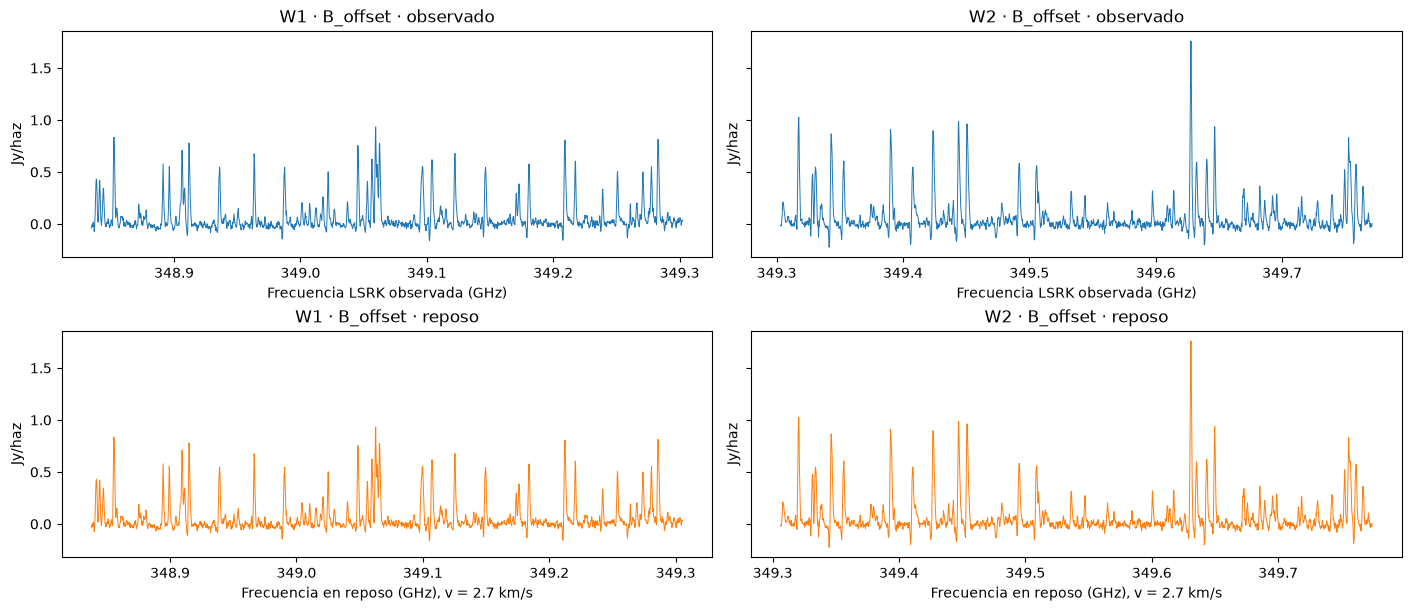

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 6), layout="constrained", sharey=True)
for col, i in enumerate((1, 2)):
    d = esp[i]
    axes[0, col].plot(d.frecuencia_LSRK_GHz, d.B_offset_Jy_beam, lw=.7)
    axes[0, col].set(xlabel="Frecuencia LSRK observada (GHz)", ylabel="Jy/haz", title=f"W{i} · B_offset · observado")
    axes[1, col].plot(d.reposo_GHz_B_offset, d.B_offset_Jy_beam, lw=.7, color="C1")
    axes[1, col].set(xlabel="Frecuencia en reposo (GHz), v = 2.7 km/s", ylabel="Jy/haz", title=f"W{i} · B_offset · reposo")
fig.savefig(FIGS / "fig1_espectro_B_offset.png", dpi=150)
plt.show()

## Figura 2 · Tres posiciones, dos ventanas (Guía, Figura 3)
Misma escala vertical, sin normalizar, sin suavizar, sin restar fondo. Cada posición con su velocidad dada.
W1 y W2 en paneles separados: no se unen (hueco de 0.736 MHz).

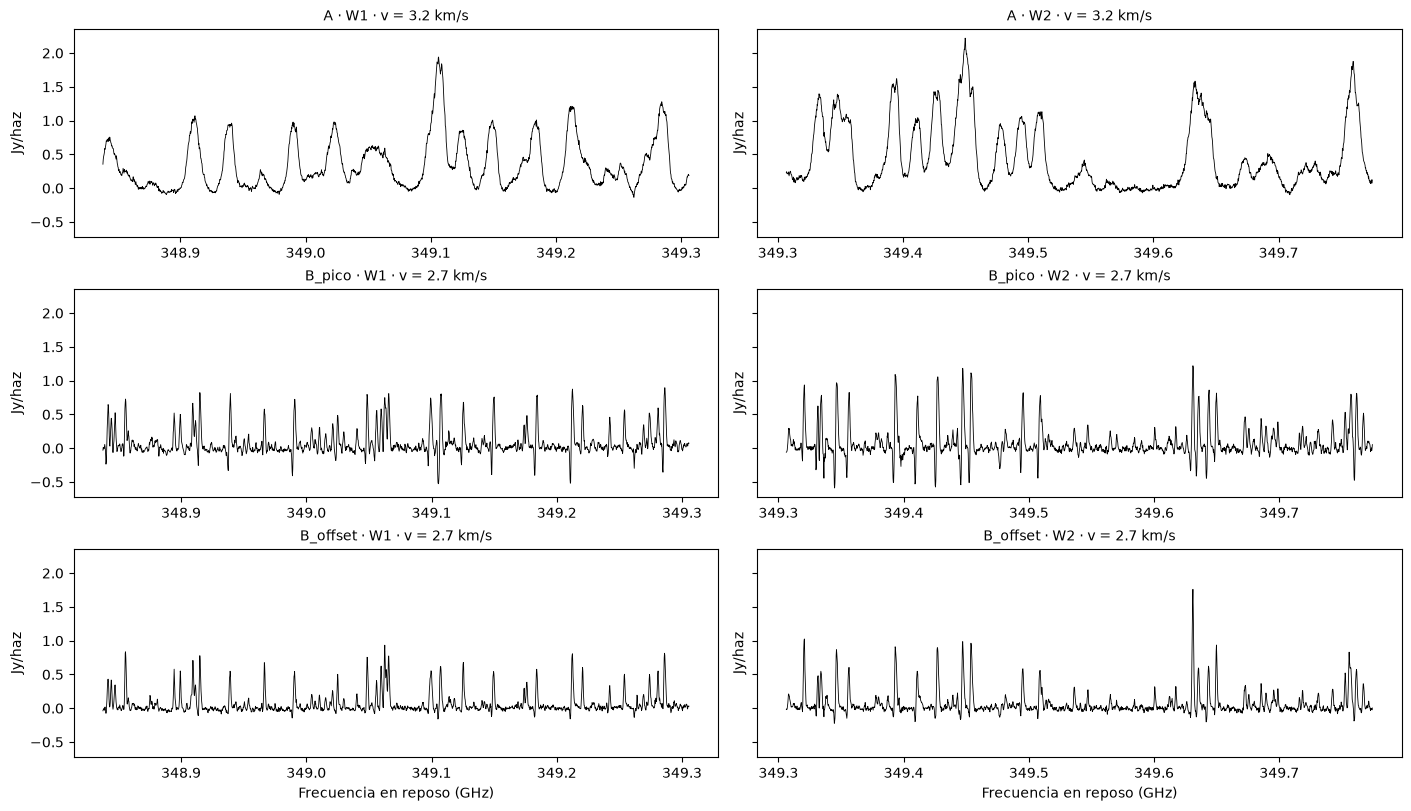

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(14, 8), layout="constrained", sharey=True)
for row, pos in enumerate(["A", "B_pico", "B_offset"]):
    for col, i in enumerate((1, 2)):
        d = esp[i]
        axes[row, col].plot(d[f"reposo_GHz_{pos}"], d[f"{pos}_Jy_beam"], lw=.6, color="k")
        axes[row, col].set_title(f"{pos} · W{i} · v = {V[pos]} km/s", fontsize=10)
        axes[row, col].set_ylabel("Jy/haz")
axes[-1, 0].set_xlabel("Frecuencia en reposo (GHz)"); axes[-1, 1].set_xlabel("Frecuencia en reposo (GHz)")
fig.savefig(FIGS / "fig2_tres_posiciones.png", dpi=150)
plt.show()

## Figura 3 · Fragmento de W1 · B_offset (diapositiva 20) con el catálogo
Mismo intervalo que la diapositiva (349.04–349.10 GHz observados), ya en reposo. Las líneas verticales son
transiciones del catálogo local **en reposo, tal como vienen**. Una coincidencia aislada es una candidata, no una identificación.

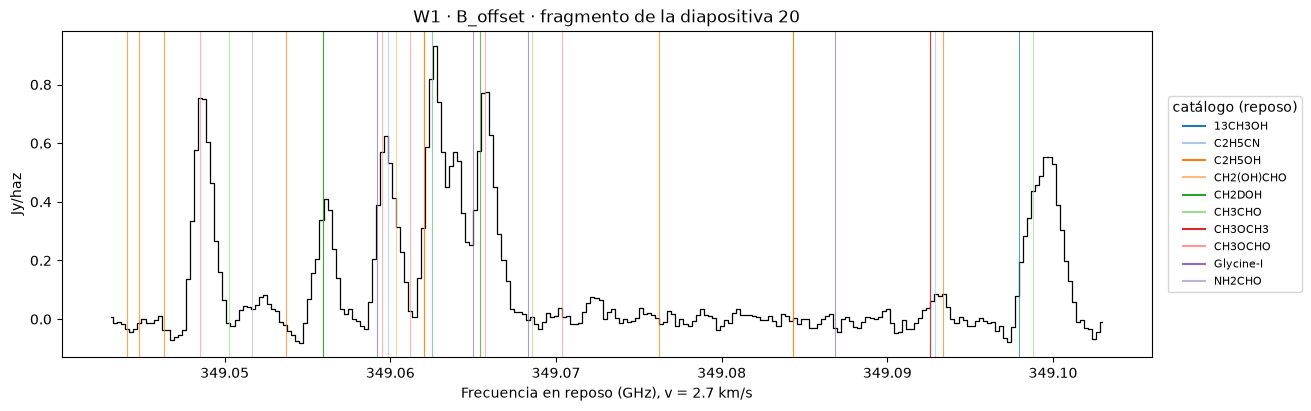

In [5]:
d = esp[1]
lo, hi = a_reposo(349.04, 2.7), a_reposo(349.10, 2.7)
m = (d.reposo_GHz_B_offset >= lo) & (d.reposo_GHz_B_offset <= hi)
fig, ax = plt.subplots(figsize=(13, 4), layout="constrained")
ax.step(d.reposo_GHz_B_offset[m], d.B_offset_Jy_beam[m], where="mid", lw=.9, color="k")
c = cat[(cat.frecuencia_reposo_MHz / 1000 >= lo) & (cat.frecuencia_reposo_MHz / 1000 <= hi)]
colores = {s: plt.cm.tab20(k) for k, s in enumerate(sorted(c.especie.unique()))}
for _, r in c.iterrows():
    ax.axvline(r.frecuencia_reposo_MHz / 1000, color=colores[r.especie], lw=.8, alpha=.7)
for s, col in colores.items():
    ax.plot([], [], color=col, label=s)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, .5), title="catálogo (reposo)")
ax.set(xlabel="Frecuencia en reposo (GHz), v = 2.7 km/s", ylabel="Jy/haz", title="W1 · B_offset · fragmento de la diapositiva 20")
fig.savefig(FIGS / "fig3_fragmento_catalogo.png", dpi=150)
plt.show()

`candidatos()` del cuaderno oficial, sin cambios, para el pico más alto del fragmento.

In [6]:
def candidatos(nu_observada_GHz, v_kms=2.7, tolerancia_MHz=1.0):
    nu_reposo_MHz = 1000*nu_observada_GHz/(1-v_kms/C)
    d = cat.assign(delta_MHz=cat.frecuencia_reposo_MHz-nu_reposo_MHz)
    return d[abs(d.delta_MHz)<=tolerancia_MHz].sort_values("delta_MHz")

frag = esp[1][(esp[1].frecuencia_LSRK_GHz >= 349.04) & (esp[1].frecuencia_LSRK_GHz <= 349.10)]
pico = frag.loc[frag.B_offset_Jy_beam.idxmax()]
print(f"Pico más alto: {pico.frecuencia_LSRK_GHz:.6f} GHz observado, {pico.B_offset_Jy_beam:.3f} Jy/haz")
candidatos(pico.frecuencia_LSRK_GHz)[["especie", "frecuencia_reposo_MHz", "incertidumbre_MHz", "E_superior_K", "delta_MHz"]]

Pico más alto: 349.059536 GHz observado, 0.933 Jy/haz


,especie,frecuencia_reposo_MHz,incertidumbre_MHz,E_superior_K,delta_MHz
92,C2H5OH,349062.0450,0.1044,993.981389,-0.634939
93,C2H5OH,349062.0450,0.1044,993.981389,-0.634939
94,Glycine-I,349062.5309,0.1970,490.309654,-0.149039
95,CH3CHO,349062.5432,0.0281,398.297284,-0.136739


## Figura 4 · Ruido empírico (cuaderno oficial)
`ruido_empirico()` sin cambios. Intervalos sin rasgos visibles: los segmentos de `analysis/outputs/ruido.csv`
(sombreados), para que cualquiera pueda revisarlos sobre la gráfica.

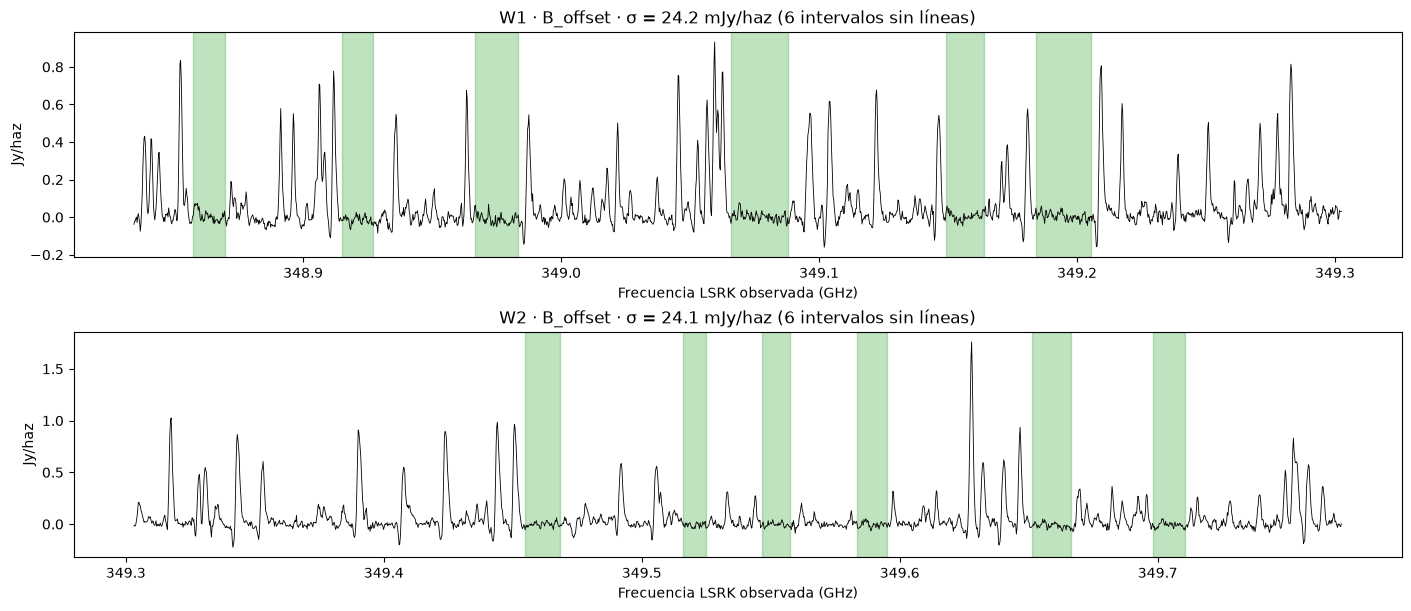

{1: np.float64(0.024177861529518438), 2: np.float64(0.02411928197329435)}

In [7]:
def ruido_empirico(ventana, intervalos_GHz, posicion="B_offset"):
    d=esp[ventana]; f=d.frecuencia_LSRK_GHz.to_numpy(); y=d[posicion+"_Jy_beam"].to_numpy()
    piezas=[]
    for lo,hi in intervalos_GHz:
        z=y[(f>=lo)&(f<=hi)]
        if len(z)<5: raise ValueError("Se requieren al menos 5 canales por intervalo")
        piezas.append(z-np.median(z))
    return np.std(np.concatenate(piezas),ddof=1)

seg = pd.read_csv(ROOT / "analysis/outputs/ruido.csv")
fig, axes = plt.subplots(2, 1, figsize=(14, 6), layout="constrained")
sigma = {}
for ax, i in zip(axes, (1, 2)):
    s = seg[(seg.ventana == f"W{i}") & (seg.posicion == "B_offset")].segmentos_GHz.iloc[0]
    intervalos = [tuple(map(float, t.split("-"))) for t in s.split("; ")]
    sigma[i] = ruido_empirico(i, intervalos)
    d = esp[i]
    ax.plot(d.frecuencia_LSRK_GHz, d.B_offset_Jy_beam, lw=.6, color="k")
    for lo_, hi_ in intervalos:
        ax.axvspan(lo_, hi_, color="C2", alpha=.3)
    ax.set(xlabel="Frecuencia LSRK observada (GHz)", ylabel="Jy/haz",
           title=f"W{i} · B_offset · σ = {sigma[i]*1000:.1f} mJy/haz ({len(intervalos)} intervalos sin líneas)")
fig.savefig(FIGS / "fig4_ruido.png", dpi=150)
plt.show()
sigma

## Figura 5 · Ajuste gaussiano local (cuaderno oficial)
`ajustar()` sin cambios, en velocidad radio. Línea de ejemplo: CH₃CN 19₀–18₀, 349453.7001 MHz en reposo
(la transición más intensa del catálogo local). El ajuste es **descriptivo**: no identifica la molécula.

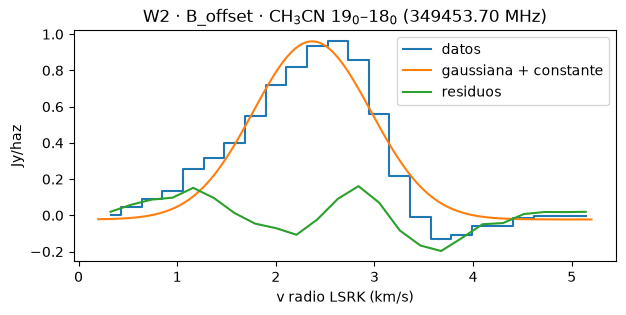

{'v_centro': np.float64(2.3685123184323773),
 'FWHM': np.float64(1.4053594594259051),
 'pico': np.float64(0.9830607530338193),
 'baseline': np.float64(-0.022675203679576653),
 'area': np.float64(1.4706184076472244),
 'errores_formales': array([0.06037003, 0.03878071, 0.04848335, 0.0340381 ]),
 'rms_residuo': np.float64(0.10151422087638383)}

In [8]:
def ajustar(ventana, nu_reposo_GHz, vmin, vmax, posicion="B_offset"):
    d=esp[ventana]; f=d.frecuencia_LSRK_GHz.to_numpy(); y=d[posicion+"_Jy_beam"].to_numpy()
    v=C*(1-f/nu_reposo_GHz); m=(v>=vmin)&(v<=vmax); x,z=v[m],y[m]
    if len(x)<9: raise ValueError("Usa una región con al menos 9 canales")
    def gauss(x,a,mu,sigma,b):return b+a*np.exp(-.5*((x-mu)/sigma)**2)
    base=np.median(z); amp=max(z)-base; mu=x[np.argmax(z)]
    par,cov=curve_fit(gauss,x,z,p0=[amp,mu,.5,base],bounds=([0,vmin,.1,-np.inf],[np.inf,vmax,3,np.inf]))
    a,mu,sd,b=par; residual=z-gauss(x,*par)
    fig,ax=plt.subplots(figsize=(7,3)); ax.step(x,z,where="mid",label="datos")
    xx=np.linspace(vmin,vmax,300);ax.plot(xx,gauss(xx,*par),label="gaussiana + constante")
    ax.plot(x,residual,label="residuos"); ax.set(xlabel="v radio LSRK (km/s)",ylabel="Jy/haz"); ax.legend()
    ax.set_title("W2 · B_offset · CH$_3$CN 19$_0$–18$_0$ (349453.70 MHz)")
    fig.savefig(FIGS / "fig5_ajuste_gaussiano.png", dpi=150, bbox_inches="tight"); plt.show()
    return dict(v_centro=mu,FWHM=2.35482*sd,pico=a,baseline=b,area=a*sd*np.sqrt(2*np.pi),errores_formales=np.sqrt(np.diag(cov)),rms_residuo=np.std(residual,ddof=4))

ajustar(ventana=2, nu_reposo_GHz=349.4537001, vmin=0.2, vmax=5.2)

## Figura 6 · Cubo y extracción verificable (cuaderno oficial)
B_offset está en (x, y) = (54, 46) en ambos recortes (índices de Python). Se comprueba que el espectro de la
tabla es exactamente el píxel del cubo, y se muestra el mapa de continuo con las tres posiciones.

W1 (1918, 64, 64) Jy/beam LSRK
W1: extracción B_offset verificada
W2 (1918, 64, 64) Jy/beam LSRK
W2: extracción B_offset verificada


Set OBSGEO-B to   -23.022886 from OBSGEO-[XYZ].
Set OBSGEO-H to     5053.796 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


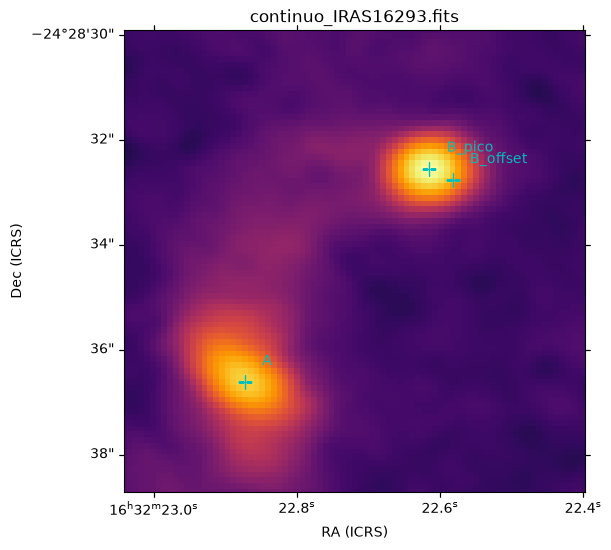

In [9]:
for i in (1, 2):
    with fits.open(BASE / f"cubos/W{i}_IRAS16293.fits", memmap=True) as hd:
        cube = hd[0].data; header = hd[0].header
        print(f"W{i}", cube.shape, header["BUNIT"], header["SPECSYS"])
        extraido = cube[:, 46, 54].copy()
    assert np.allclose(extraido, esp[i].B_offset_Jy_beam, rtol=1e-7, atol=1e-9)
    print(f"W{i}: extracción B_offset verificada")

from astropy.wcs import WCS
with fits.open(DATA / "cubos/continuo_IRAS16293.fits") as hd:
    img = np.squeeze(hd[0].data); w = WCS(hd[0].header).celestial
pos = {"B_offset": (248.0940936441, -24.4757700223), "B_pico": (248.09422793, -24.47570891), "A": (248.09530226, -24.47683947)}
fig = plt.figure(figsize=(6, 5.5), layout="constrained"); ax = fig.add_subplot(projection=w)
ax.imshow(np.arcsinh(img / np.nanstd(img)), origin="lower", cmap="inferno")
for k, (ra, dec) in pos.items():
    x, y = w.world_to_pixel_values(ra, dec); ax.plot(x, y, "c+", ms=10); ax.text(x + 3, y + 3, k, color="c")
ax.set(xlim=(128 - 40, 128 + 40), ylim=(128 - 40, 128 + 40), xlabel="RA (ICRS)", ylabel="Dec (ICRS)", title="continuo_IRAS16293.fits")
fig.savefig(FIGS / "fig6_continuo_posiciones.png", dpi=150); plt.show()

## Créditos
This package makes use of the following ALMA data: ADS/JAO.ALMA#2013.1.00278.S. Productos ARI-L.
Contexto PILS: Jørgensen et al. 2016, A&A 595, A117. Catálogos CDMS y JPL (`data/catalogos/procedencia_catalogos.json`).
Funciones `candidatos`, `ruido_empirico` y `ajustar` copiadas del cuaderno oficial `Inicio_AstroHack.ipynb`.